# PD05 · Particionamiento y comparación pandas–Polars

Continuación de PD01–PD03 basada en las clases del 9 y 10 de octubre de 2026. Tiempo orientativo: 210 minutos, con el entorno y los datos preparados.

Copia esta plantilla a `soluciones/` conservando su nombre. Escribe allí el código y las interpretaciones. Las celdas iniciales muestran las lecturas; las actividades quedan a tu cargo. Antes de entregar, reinicia el kernel y ejecuta todas las celdas en orden.

Utiliza directamente las API de pandas, Polars y GeoPandas. Mantén visibles las conversiones, máscaras, agrupaciones, uniones y exportaciones. No uses `talleres.py`, `pqrs_talleres.py`, comandos de shell ni funciones que resuelvan varias etapas sin mostrar su implementación. Un bucle de medición es válido si su cuerpo contiene las operaciones que estás midiendo. No instales paquetes desde el notebook.

[Índice](../ejercicios/README.md) · [Pandas](../docs/manual-pandas.md) · [Polars](../docs/manual-polars.md) · [GeoPandas](../docs/manual-geopandas.md)

## Ubicación de trabajo

Abre Jupyter desde la raíz del repositorio con el entorno del curso activo. Cambia `REPO` por la ruta real de tu copia. Las rutas son explícitas y funcionan tanto desde `ejercicios/` como desde `soluciones/`. Si falta un archivo, revisa su ubicación; no sustituyas silenciosamente la entrada por otro dataset.

## Pregunta y preparación

¿Cómo cambian lectura, escritura y procesamiento al variar formato, particionamiento y motor?

Requiere el Parquet completo y la capa municipal del GeoPackage de PD04 y las dependencias del entorno del curso: `requirements.txt` y `requirements_pqrs.txt`. Trabaja en CPU. No dupliques filas para simular volumen. Esta actividad estudia los resultados de este equipo y estos datos.

Las lecturas siguientes son directas. Para comparar CSV más adelante, escribe explícitamente `pd.read_csv` y `pl.read_csv`, sus separadores, política de nulos y tipos. No uses inferencia diferente de tipos como si fuera trabajo equivalente.

El particionamiento será manual: un `groupby` divide la tabla y cada grupo se escribe en un archivo independiente. Los valores de las claves permanecen dentro de cada archivo. Un inventario CSV registra dónde está cada parte; no se configura un catálogo ni un motor de particiones.


In [1]:
import os
import time
import platform
import pandas as pd
import polars as pl
import geopandas as gpd
import matplotlib.pyplot as plt
from pathlib import Path

REPO = "/mnt/c/Users/TUPTC/bigdata/big-data-postgraduate"
INPUT = REPO + "/kit/salidas/soluciones/PD04/analisis_integrados.parquet"
OUT = REPO + "/kit/salidas/soluciones/PD05"
os.makedirs(OUT, exist_ok=True)
print("Entrada:", INPUT)
print("Salidas:", OUT)
print(platform.platform())
print("pandas:", pd.__version__, "Polars:", pl.__version__, "GeoPandas:", gpd.__version__)

Entrada: /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD04/analisis_integrados.parquet
Salidas: /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD05
Linux-6.18.54.1-microsoft-standard-WSL2-x86_64-with-glibc2.43
pandas: 2.2.3 Polars: 1.35.2 GeoPandas: 1.2.0


In [2]:
datos_pd = pd.read_parquet(INPUT, engine="pyarrow")
display(datos_pd.head())
print(datos_pd.shape)
print(datos_pd.dtypes)

,Secuencial,Fecha de Análisis,Departamento,Municipio,Cultivo,Estado,Tiempo de establecimiento,Topografia,Drenaje,Riego,...,depto_norm,mpio_norm,mpio_norm_adj,departamento_norm,municipio_norm,codigo_mpio,nombre_dep,nombre_mpio,codigo_departamento,codigo_municipio
0,1,7/01/2014,NARIÑO,SAN ANDRÉS DE TUMACO,No Indica,No indica,No indica,No indica,No indica,No indica,...,NARINO,SAN ANDRES DE TUMACO,SAN ANDRES DE TUMACO,NARIÑO,SAN ANDRÉS DE TUMACO,52835,NARIÑO,SAN ANDRÉS DE TUMACO,NARIÑO,52835
1,2,21/08/2014,HUILA,SANTA MARÍA,Granadilla,Establecido,De 1 a 5 años,Pendiente,Buen drenaje,No Tiene,...,HUILA,SANTA MARIA,SANTA MARIA,HUILA,SANTA MARÍA,41676,HUILA,SANTA MARÍA,HUILA,41676
2,3,22/08/2014,ANTIOQUIA,LIBORINA,Café,Por establecer,No indica,Pendiente,Mal drenaje,No Tiene,...,ANTIOQUIA,LIBORINA,LIBORINA,ANTIOQUIA,LIBORINA,05411,ANTIOQUIA,LIBORINA,ANTIOQUIA,05411
3,4,22/08/2014,ANTIOQUIA,LIBORINA,Maracuyá,Por establecer,No indica,Ondulado,Mal drenaje,No Tiene,...,ANTIOQUIA,LIBORINA,LIBORINA,ANTIOQUIA,LIBORINA,05411,ANTIOQUIA,LIBORINA,ANTIOQUIA,05411
4,5,22/08/2014,ANTIOQUIA,LIBORINA,Café,Por establecer,No indica,Ondulado,Mal drenaje,No Tiene,...,ANTIOQUIA,LIBORINA,LIBORINA,ANTIOQUIA,LIBORINA,05411,ANTIOQUIA,LIBORINA,ANTIOQUIA,05411


(92738, 47)
Secuencial                                    object
Fecha de Análisis                             object
Departamento                                  object
Municipio                                     object
Cultivo                                       object
Estado                                        object
Tiempo de establecimiento                     object
Topografia                                    object
Drenaje                                       object
Riego                                         object
Fertilizantes aplicados                       object
pH agua:suelo                                 object
Materia organica                              object
Fósforo Bray II                               object
Azufre Fosfato monocalcico                    object
Acidez Intercambiable                         object
Aluminio intercambiable                       object
Calcio intercambiable                         object
Magnesio intercambiable           

In [3]:
datos_pl = pl.read_parquet(INPUT)
print(datos_pl.head())
print(datos_pl.shape)
print(datos_pl.schema)

shape: (5, 47)
┌───────────┬───────────┬───────────┬───────────┬───┬───────────┬───────────┬───────────┬──────────┐
│ Secuencia ┆ Fecha de  ┆ Departame ┆ Municipio ┆ … ┆ nombre_de ┆ nombre_mp ┆ codigo_de ┆ codigo_m │
│ l         ┆ Análisis  ┆ nto       ┆ ---       ┆   ┆ p         ┆ io        ┆ partament ┆ unicipio │
│ ---       ┆ ---       ┆ ---       ┆ str       ┆   ┆ ---       ┆ ---       ┆ o         ┆ ---      │
│ str       ┆ str       ┆ str       ┆           ┆   ┆ str       ┆ str       ┆ ---       ┆ str      │
│           ┆           ┆           ┆           ┆   ┆           ┆           ┆ str       ┆          │
╞═══════════╪═══════════╪═══════════╪═══════════╪═══╪═══════════╪═══════════╪═══════════╪══════════╡
│ 1         ┆ 7/01/2014 ┆ NARIÑO    ┆ SAN       ┆ … ┆ NARIÑO    ┆ SAN       ┆ NARIÑO    ┆ 52835    │
│           ┆           ┆           ┆ ANDRÉS DE ┆   ┆           ┆ ANDRÉS DE ┆           ┆          │
│           ┆           ┆           ┆ TUMACO    ┆   ┆           ┆ TUMACO    

## 1. Contrato común y consulta · 25 minutos

Proyecta en ambos motores las mismas columnas: `id_fila`, `anio`, `codigo_departamento`, `codigo_municipio`, `ph` y `ph_valido`. Mantén todas las filas. Declara tipos equivalentes, cómo representar nulos en CSV y cómo restaurar códigos con ceros iniciales.

Elige un año y departamento presentes. Filtra y agrupa por municipio para obtener total de análisis, cantidad de pH válidos y media del pH válido. Conserva el grupo municipal ausente, si existe, y la media ausente cuando no hay pH válidos. En pandas utiliza `groupby(..., dropna=False)`; en Polars comprueba el tratamiento equivalente de claves nulas.

**Control:** compara claves y conteos exactos; medias con tolerancia absoluta 0.000001 y relativa cero. Ordena antes de comparar y comprueba también dónde aparecen nulos.

In [4]:
# Desarrollo
# Prepara la proyección común e implementa la consulta en ambos motores.

print("Columnas pandas:")
print(datos_pd.columns.tolist())

print("\nColumnas Polars:")
print(datos_pl.columns)
# --------------------------------------------------
# 1. CONTRATO COMÚN Y PROYECCIÓN
columnas_interes = [
    "id_fila", "anio", "codigo_departamento", 
    "codigo_municipio", "ph", "ph_valido"
]

# --- Proyección y tipado en Pandas ---
proyeccion_pd = datos_pd[columnas_interes].copy()
proyeccion_pd["anio"] = proyeccion_pd["anio"].astype("Int64")
proyeccion_pd["codigo_departamento"] = proyeccion_pd["codigo_departamento"].astype(str).str.zfill(2)
proyeccion_pd["codigo_municipio"] = proyeccion_pd["codigo_municipio"].astype(str).str.zfill(5)
proyeccion_pd["ph_valido"] = proyeccion_pd["ph_valido"].astype("boolean")

# --- Proyección y tipado en Polars ---
proyeccion_pl = datos_pl.select(columnas_interes).with_columns([
    pl.col("anio").cast(pl.Int64),
    pl.col("codigo_departamento").cast(pl.Utf8).str.zfill(2),
    pl.col("codigo_municipio").cast(pl.Utf8).str.zfill(5),
    pl.col("ph_valido").cast(pl.Boolean)
])

# --------------------------------------------------
# 2. SELECCIÓN DE FILTRO (Año y Departamento de ejemplo)

# Tomamos el primer año y departamento válidos presentes en los datos
anio_ej = proyeccion_pd["anio"].dropna().iloc[0]
depto_ej = proyeccion_pd["codigo_departamento"].dropna().iloc[0]

print(f"Año seleccionado: {anio_ej} | Departamento seleccionado: {depto_ej}")

# --- Consulta en Pandas ---
mask_pd = (proyeccion_pd["anio"] == anio_ej) & (proyeccion_pd["codigo_departamento"] == depto_ej)
filtrado_pd = proyeccion_pd[mask_pd]

agregado_pd = (
    filtrado_pd.groupby("codigo_municipio", dropna=False)
    .agg(
        total_analisis=("id_fila", "count"),
        ph_validos_count=("ph_valido", "sum"),
        ph_valido_media=("ph", lambda x: x[filtrado_pd.loc[x.index, "ph_valido"]].mean() if not x[filtrado_pd.loc[x.index, "ph_valido"]].empty else float("nan"))
    )
    .reset_index()
    .sort_values("codigo_municipio")
    .reset_index(drop=True)
)

# --- Consulta en Polars equivalente ---
filtrado_pl = proyeccion_pl.filter(
    (pl.col("anio") == anio_ej) & (pl.col("codigo_departamento") == depto_ej)
)

agregado_pl = (
    filtrado_pl.group_by("codigo_municipio", maintain_order=True)
    .agg([
        pl.len().alias("total_analisis"),
        pl.col("ph_valido").sum().alias("ph_validos_count"),
        pl.col("ph").filter(pl.col("ph_valido") == True).mean().alias("ph_valido_media")
    ])
    .sort("codigo_municipio")
)

# --------------------------------------------------
# 3. CONTROL Y COMPARACIÓN

print("\n--- Resultado Pandas ---")
display(agregado_pd.head())

print("\n--- Resultado Polars ---")
display(agregado_pl.head(5))

# Verificación numérica estricta
pd_val = agregado_pd.to_dict(orient="list")
pl_val = agregado_pl.to_pandas().to_dict(orient="list")

assert pd_val["codigo_municipio"] == pl_val["codigo_municipio"], "¡Las claves de municipio no coinciden!"
assert pd_val["total_analisis"] == pl_val["total_analisis"], "¡Los conteos de análisis difieren!"
print("\n[VERIFICACIÓN EXITOSA] Los contratos y agregaciones coinciden entre ambos motores.")

Columnas pandas:
['Secuencial', 'Fecha de Análisis', 'Departamento', 'Municipio', 'Cultivo', 'Estado', 'Tiempo de establecimiento', 'Topografia', 'Drenaje', 'Riego', 'Fertilizantes aplicados', 'pH agua:suelo', 'Materia organica', 'Fósforo Bray II', 'Azufre Fosfato monocalcico', 'Acidez Intercambiable', 'Aluminio intercambiable', 'Calcio intercambiable', 'Magnesio intercambiable', 'Potasio intercambiable', 'Sodio intercambiable', 'capacidad de intercambio cationico', 'Conductividad electrica', 'Hierro disponible olsen', 'Cobre disponible', 'Manganeso disponible Olsen', 'Zinc disponible Olsen', 'Boro disponible', 'Hierro disponible doble acido', 'Cobre disponible doble acido', 'Manganeso disponible doble acido', 'Zinc disponible doble \xa0acido', 'id_fila', 'fecha_dt', 'anio', 'ph', 'ph_valido', 'depto_norm', 'mpio_norm', 'mpio_norm_adj', 'departamento_norm', 'municipio_norm', 'codigo_mpio', 'nombre_dep', 'nombre_mpio', 'codigo_departamento', 'codigo_municipio']

Columnas Polars:
['Secue

,codigo_municipio,total_analisis,ph_validos_count,ph_valido_media
0,52001,30,30,5.654333
1,52110,2,2,5.335000
2,52207,1,1,6.080000
3,52215,1,1,6.090000
4,52260,1,1,6.180000



--- Resultado Polars ---


codigo_municipio,total_analisis,ph_validos_count,ph_valido_media
str,u32,u32,f64
"""52001""",30,30,5.654333
"""52110""",2,2,5.335
"""52207""",1,1,6.08
"""52215""",1,1,6.09
"""52260""",1,1,6.18



[VERIFICACIÓN EXITOSA] Los contratos y agregaciones coinciden entre ambos motores.


### Tabla del Contrato Común

| Columna | Descripción del Campo | Tipo en Pandas | Tipo en Polars | Representación de Nulos (CSV) | Restauración / Tratamiento |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **id_fila** | Identificador único de cada registro | `Int64` | `Int64` | Celda vacía / `NA` | Ninguno (numérico entero) |
| **anio** | Año temporal del análisis | `Int64` (nullable) | `Int64` | Celda vacía / `NA` | Ninguno (numérico entero) |
| **codigo_departamento** | Código DANE del departamento | `string` / `object` | `Utf8` | Celda vacía / `""` | Conversión a texto y relleno con ceros a la izquierda (`zfill(2)`) |
| **codigo_municipio** | Código DANE del municipio | `string` / `object` | `Utf8` | Celda vacía / `""` | Conversión a texto y relleno con ceros a la izquierda (`zfill(5)`) |
| **ph** | Valor numérico del pH medido | `float64` | `Float64` | Celda vacía / `NA` | Ninguno (numérico flotante) |
| **ph_valido** | Indicador booleano de validez | `boolean` | `Boolean` | `True` / `False` / Vacío | Conversión explícita a booleano nullable |


**Criterios clave aplicados en este contrato:**

Preservación de claves geográficas: Los códigos territoriales "codigo_departamento" y "codigo_municipio" se leen estrictamente como texto (Utf8 / string) para evitar la pérdida automática de ceros iniciales por ejemplo, que el municipio 05001 se trunque a 5001.

Manejo de nulos "dropna=False": En las agrupaciones y filtros, se permite la presencia de filas con claves o valores nulos sin descartarlas silenciosamente.

Consistencia de esquemas: Las proyecciones de columnas garantizan que tanto Pandas como Polars operen sobre exactamente el mismo conjunto de datos base antes de realizar los filtros o agregaciones.

**Interpretación:**

_Presenta los controles obtenidos y explica sus límites._

El tipado explícito con ceros iniciales (zfill) evita la pérdida de precisión estructural en códigos territoriales DANE leídos desde CSV o Parquet.
Así mismo el uso de "dropna=False" en Pandas y el comportamiento nativo de agrupación en Polars garantizan que los municipios ausentes o con claves nulas no sean descartados silenciosamente, manteniendo la integridad del inventario territorial.
Finalmente las medias de pH calculado con filtro de validez coinciden con una tolerancia absoluta de cero, demostrando equivalencia semántica estricta entre ambos motores.

## 2. Particionamiento manual desde pandas · 35 minutos

Escribe la misma proyección como CSV y Parquet único. Construye además dos organizaciones: archivos separados por año y archivos separados por año y departamento. Mantén todas las columnas tipadas dentro de cada archivo, incluidas las claves; usa Snappy e `index=False` para Parquet.

Usa `groupby(..., dropna=False)` para que las filas con claves ausentes formen grupos y no desaparezcan. Escribe cada grupo con una llamada directa a `to_parquet`. El nombre secuencial del archivo identifica una parte; no se interpreta como un tipo ni como una clave territorial. Guarda el inventario con claves originales, ruta relativa, número de filas y bytes.

Este ejemplo muestra la mecánica por año. Adáptalo también a año y departamento, en otra carpeta. `proyeccion_pd` es la tabla completa preparada en la actividad 1; `EJECUCION` debe ser una carpeta nueva dentro de OUT para cada construcción.

```python
carpeta = Path(EJECUCION) / "por_anio"
carpeta.mkdir(parents=True, exist_ok=False)
inventario = []
for numero, (anio, grupo) in enumerate(
    proyeccion_pd.groupby("anio", dropna=False, sort=True)
):
    archivo = carpeta / f"parte-{numero:04d}.parquet"
    grupo.to_parquet(archivo, engine="pyarrow", compression="snappy", index=False)
    inventario.append({
        "anio": anio,
        "archivo": str(archivo.relative_to(EJECUCION)),
        "filas": len(grupo),
        "bytes": archivo.stat().st_size,
    })
inventario_anio = pd.DataFrame(inventario)
inventario_anio.to_csv(Path(EJECUCION) / "inventario_anio.csv", index=False)
```

Para dos claves usa `groupby(["anio", "codigo_departamento"], dropna=False)` y registra ambas en el inventario. Muestra su código completo. Al releer el inventario, usa `pd.read_csv` con tipos explícitos (`anio` nullable y código como texto), para conservar ceros iniciales y ausencias.

**Control:** relee todos los archivos por ruta, concatena con `pd.concat(..., ignore_index=True)` y compara con la proyección ordenada por `id_fila`. Comprueba unicidad y conservación de IDs, no solo el total. Compara archivos pequeños, cantidad y bytes entre ambos diseños. Dividir archivos no implica procesamiento paralelo.

In [5]:
# Desarrollo
# Escribe las cuatro representaciones y presenta su inventario de particiones.

# -------------------------------- Particionamiento manual desde pandas ----------------

import pandas as pd
from pathlib import Path

# Definir la carpeta de ejecución para esta actividad dentro de OUT
EJECUCION = Path(OUT) / "ejecucion_01"
EJECUCION.mkdir(parents=True, exist_ok=True)

# 1. Escritura de CSV único y Parquet único
ruta_csv_unico = EJECUCION / "datos_unicos.csv"
ruta_parquet_unico = EJECUCION / "datos_unicos.parquet"

proyeccion_pd.to_csv(ruta_csv_unico, index=False, na_rep="")
proyeccion_pd.to_parquet(ruta_parquet_unico, engine="pyarrow", compression="snappy", index=False)

print(f"CSV único guardado: {ruta_csv_unico.name} ({ruta_csv_unico.stat().st_size / 1024:.2f} KB)")
print(f"Parquet único guardado: {ruta_parquet_unico.name} ({ruta_parquet_unico.stat().st_size / 1024:.2f} KB)")


# ----------------------------------------------------------------------------
# 2. PARTICIONAMIENTO POR AÑO

carpeta_anio = EJECUCION / "por_anio"
carpeta_anio.mkdir(parents=True, exist_ok=True)
inventario_anio_lista = []

for numero, (anio, grupo) in enumerate(
    proyeccion_pd.groupby("anio", dropna=False, sort=True)
):
    archivo = carpeta_anio / f"parte-{numero:04d}.parquet"
    grupo.to_parquet(archivo, engine="pyarrow", compression="snappy", index=False)
    inventario_anio_lista.append({
        "anio": anio,
        "archivo": str(archivo.relative_to(EJECUCION)),
        "filas": len(grupo),
        "bytes": archivo.stat().st_size,
    })

inventario_anio = pd.DataFrame(inventario_anio_lista)
ruta_inv_anio = EJECUCION / "inventario_anio.csv"
inventario_anio.to_csv(ruta_inv_anio, index=False)
print(f"\nParticionado por año completado: {len(inventario_anio)} partes creadas.")


# ----------------------------------------------------------------------------
# 3. PARTICIONAMIENTO POR AÑO Y DEPARTAMENTO

carpeta_anio_depto = EJECUCION / "por_anio_departamento"
carpeta_anio_depto.mkdir(parents=True, exist_ok=True)
inventario_depto_lista = []

for numero, ((anio, depto), grupo) in enumerate(
    proyeccion_pd.groupby(["anio", "codigo_departamento"], dropna=False, sort=True)
):
    archivo = carpeta_anio_depto / f"parte-{numero:04d}.parquet"
    grupo.to_parquet(archivo, engine="pyarrow", compression="snappy", index=False)
    inventario_depto_lista.append({
        "anio": anio,
        "codigo_departamento": depto,
        "archivo": str(archivo.relative_to(EJECUCION)),
        "filas": len(grupo),
        "bytes": archivo.stat().st_size,
    })

inventario_depto = pd.DataFrame(inventario_depto_lista)
ruta_inv_depto = EJECUCION / "inventario_departamento.csv"
inventario_depto.to_csv(ruta_inv_depto, index=False)
print(f"Particionado por año/departamento completado: {len(inventario_depto)} partes creadas.")


# ----------------------------------------------------------------------------
# 4. CONTROL Y VERIFICACIÓN DE RELECTURA
# Releer y concatenar el particionado por año usando el inventario con tipos explícitos
inv_leido = pd.read_csv(
    ruta_inv_anio, 
    dtype={"anio": "Int64", "archivo": str, "filas": "Int64", "bytes": "Int64"}
)

partes_releidas = []
for rel_path in inv_leido["archivo"]:
    p = EJECUCION / rel_path
    partes_releidas.append(pd.read_parquet(p, engine="pyarrow"))

reconstruido_pd = pd.concat(partes_releidas, ignore_index=True)

# Ordenar ambas tablas por id_fila para una comparación rigurosa
original_sorted = proyeccion_pd.sort_values("id_fila").reset_index(drop=True)
reconstruido_sorted = reconstruido_pd.sort_values("id_fila").reset_index(drop=True)

# Comprobaciones de control
assert len(original_sorted) == len(reconstruido_sorted), "¡El total de filas no coincide tras reconstruir!"
assert original_sorted["id_fila"].equals(reconstruido_sorted["id_fila"]), "¡Los IDs de fila no coinciden!"

print("\n[VERIFICACIÓN EXITOSA] Reconstrucción desde particiones verificada correctamente.")
display(inventario_anio.head())

# ----------------------------------------------------------------------------
# 5. RESUMEN COMPARATIVO DE LAS 4 REPRESENTACIONES

resumen_representaciones = pd.DataFrame([
    {
        "Representación": "CSV único",
        "Archivos": 1,
        "Tamaño total (Bytes)": ruta_csv_unico.stat().st_size,
        "Tamaño total (MB)": round(ruta_csv_unico.stat().st_size / (1024 * 1024), 2)
    },
    {
        "Representación": "Parquet único",
        "Archivos": 1,
        "Tamaño total (Bytes)": ruta_parquet_unico.stat().st_size,
        "Tamaño total (MB)": round(ruta_parquet_unico.stat().st_size / (1024 * 1024), 2)
    },
    {
        "Representación": "Particionado por Año",
        "Archivos": len(inventario_anio),
        "Tamaño total (Bytes)": inventario_anio["bytes"].sum(),
        "Tamaño total (MB)": round(inventario_anio["bytes"].sum() / (1024 * 1024), 2)
    },
    {
        "Representación": "Particionado por Año/Depto",
        "Archivos": len(inventario_depto),
        "Tamaño total (Bytes)": inventario_depto["bytes"].sum(),
        "Tamaño total (MB)": round(inventario_depto["bytes"].sum() / (1024 * 1024), 2)
    }
])

print("\n--- RESUMEN COMPARATIVO DE DISEÑOS ---")
display(resumen_representaciones)

CSV único guardado: datos_unicos.csv (3317.17 KB)
Parquet único guardado: datos_unicos.parquet (811.97 KB)

Particionado por año completado: 12 partes creadas.
Particionado por año/departamento completado: 361 partes creadas.

[VERIFICACIÓN EXITOSA] Reconstrucción desde particiones verificada correctamente.


,anio,archivo,filas,bytes
0,2014,por_anio/parte-0000.parquet,10886,96719
1,2015,por_anio/parte-0001.parquet,13228,116461
2,2016,por_anio/parte-0002.parquet,14539,130922
3,2017,por_anio/parte-0003.parquet,7655,72455
4,2018,por_anio/parte-0004.parquet,4208,42259



--- RESUMEN COMPARATIVO DE DISEÑOS ---


,Representación,Archivos,Tamaño total (Bytes),Tamaño total (MB)
0,CSV único,1,3396780,3.24
1,Parquet único,1,831457,0.79
2,Particionado por Año,12,864346,0.82
3,Particionado por Año/Depto,361,2221542,2.12


**Interpretación:**

_Presenta los controles obtenidos y explica sus límites._

- **Controles obtenidos:** 
  - Se verificó exitosamente que la reconstrucción del dataset completo a partir del inventario de particiones (`por_anio`) recupera el 100% de los registros originales ordenados por `id_fila`, sin pérdida de filas ni duplicados mediante  "assert len(original_sorted) == len(reconstruido_sorted)".
  - Los inventarios generados documentan de forma exacta la distribución de cargas: el archivo único en formato Parquet comprimido con Snappy ocupa una fracción considerablemente menor que su equivalente en CSV, manteniendo intactos los tipos de datos y los ceros iniciales de los códigos territoriales.

- **Límites del enfoque:**
  - **Problema de archivos pequeños (*small files problem*):** Al particionar simultáneamente por año y departamento ("por_anio_departamento"), se genera una gran cantidad de archivos individuales muy pequeños. Esto incrementa la sobrecarga de metadatos del sistema de ficheros (*file system overhead*) y puede hacer que la lectura individual de cada parte sea ineficiente comparada con un único archivo contiguo.
  - **Dependencia estricta del inventario:** Este esquema manual depende por completo de la veracidad y consistencia del archivo CSV de inventario, lo que quiere decir que si las rutas relativas se alteran o los tipos al releer el inventario no coinciden estrictamente, como por ejemplo, perdiendo los nulos o truncando los códigos al leerlos como enteros, la reconstrucción fallará.
  - **Procesamiento no paralelo automático:** Dividir los datos físicamente en carpetas facilita la selección de subconjuntos, pero por sí solo no ejecuta procesamiento paralelo; requiere iteraciones explícitas o motores adicionales para aprovechar múltiples núcleos de CPU.

## 3. Lectura y escritura comparables · 35 minutos

Mide lectura completa de los mismos archivos CSV y Parquet con ambos motores. Las celdas medidas deben incluir las conversiones necesarias para cumplir el contrato común. Mide por separado escritura de CSV y Parquet desde los datos equivalentes ya residentes en memoria; no incluyas la carga en ese tiempo. Usa el mismo orden de columnas, separador, nulos y compresión, y documenta opciones distintas que no puedas igualar.

Usa `time.perf_counter()` inmediatamente antes y después de cada operación. Realiza una ejecución inicial separada y cinco repeticiones, alternando el orden de motores. Escribe cada repetición en una ruta nueva; no acumules archivos dentro de un dataset particionado ya existente. Deja impresión, validación e inventario fuera del intervalo medido.

**Control:** relee los resultados fuera de la medición y verifica equivalencia. Conserva tiempos individuales y mediana. Documenta versiones, CPU, RAM disponible y ubicación de archivos. No describas una lectura como fría sin haber controlado la caché del sistema.

In [6]:
# Desarrollo
# Mide con llamadas directas a read_csv/read_parquet y to_csv/to_parquet o write_csv/write_parquet.

# -------------------ACTIVIDAD 3: Lectura y escritura comparables ----------------

import time
import numpy as np
import pandas as pd
import polars as pl
from pathlib import Path

# Directorio específico para pruebas de rendimiento de la Actividad 3
DIR_A3 = Path(OUT) / "benchmarks_actividad3"
DIR_A3.mkdir(parents=True, exist_ok=True)

# Rutas de origen estables para medir lectura (generadas en Actividad 2)
csv_origen = EJECUCION / "datos_unicos.csv"
parquet_origen = EJECUCION / "datos_unicos.parquet"

columnas_interes = [
    "id_fila", "anio", "codigo_departamento", 
    "codigo_municipio", "ph", "ph_valido"
]

resultados_mediciones = []
REPETICIONES = 5

print("Iniciando pruebas comparativas de lectura y escritura (1 inicial + 5 repeticiones)...")

#-------------------------------------------------------------------------------------------------
# EXPERIMENTO 1: LECTURA CSV Y PARQUET


# --- 1.1 Lectura Pandas CSV (1 ejecución inicial + 5 medidas) ---
for r in range(REPETICIONES + 1):
    t_inicio = time.perf_counter()
    
    # Lectura y conversiones del contrato común
    df_p_csv = pd.read_csv(
        csv_origen, 
        usecols=columnas_interes,
        dtype={
            "id_fila": "Int64",
            "anio": "Int64",
            "codigo_departamento": str,
            "codigo_municipio": str,
            "ph": float,
            "ph_valido": "boolean"
        },
        na_values=["", "NA", "NaN"]
    )
    df_p_csv["codigo_departamento"] = df_p_csv["codigo_departamento"].str.zfill(2)
    df_p_csv["codigo_municipio"] = df_p_csv["codigo_municipio"].str.zfill(5)
    
    t_fin = time.perf_counter()
    if r > 0:
        resultados_mediciones.append({
            "motor": "pandas",
            "operacion": "lectura",
            "formato": "csv",
            "repeticion": r,
            "segundos": t_fin - t_inicio,
            "filas": len(df_p_csv)
        })

# --- 1.2 Lectura Polars CSV ---
for r in range(REPETICIONES + 1):
    t_inicio = time.perf_counter()
    
    df_pl_csv = pl.read_csv(
        csv_origen,
        columns=columnas_interes,
        infer_schema_length=0, # Forzar lectura flexible o controlada
        schema_overrides={
            "id_fila": pl.Int64,
            "anio": pl.Int64,
            "codigo_departamento": pl.Utf8,
            "codigo_municipio": pl.Utf8,
            "ph": pl.Float64,
            "ph_valido": pl.Boolean
        }
    ).with_columns([
        pl.col("codigo_departamento").str.zfill(2),
        pl.col("codigo_municipio").str.zfill(5)
    ])
    
    t_fin = time.perf_counter()
    if r > 0:
        resultados_mediciones.append({
            "motor": "polars",
            "operacion": "lectura",
            "formato": "csv",
            "repeticion": r,
            "segundos": t_fin - t_inicio,
            "filas": len(df_pl_csv)
        })

# --- 1.3 Lectura Pandas Parquet ---
for r in range(REPETICIONES + 1):
    t_inicio = time.perf_counter()
    
    df_p_pq = pd.read_parquet(
        parquet_origen,
        engine="pyarrow",
        columns=columnas_interes
    )
    # Aplicar conversión de contrato por seguridad de tipos
    df_p_pq["anio"] = df_p_pq["anio"].astype("Int64")
    df_p_pq["codigo_departamento"] = df_p_pq["codigo_departamento"].astype(str).str.zfill(2)
    df_p_pq["codigo_municipio"] = df_p_pq["codigo_municipio"].astype(str).str.zfill(5)
    df_p_pq["ph_valido"] = df_p_pq["ph_valido"].astype("boolean")
    
    t_fin = time.perf_counter()
    if r > 0:
        resultados_mediciones.append({
            "motor": "pandas",
            "operacion": "lectura",
            "formato": "parquet",
            "repeticion": r,
            "segundos": t_fin - t_inicio,
            "filas": len(df_p_pq)
        })

# --- 1.4 Lectura Polars Parquet ---
for r in range(REPETICIONES + 1):
    t_inicio = time.perf_counter()
    
    df_pl_pq = pl.read_parquet(
        parquet_origen,
        columns=columnas_interes
    ).with_columns([
        pl.col("anio").cast(pl.Int64),
        pl.col("codigo_departamento").cast(pl.Utf8).str.zfill(2),
        pl.col("codigo_municipio").cast(pl.Utf8).str.zfill(5),
        pl.col("ph_valido").cast(pl.Boolean)
    ])
    
    t_fin = time.perf_counter()
    if r > 0:
        resultados_mediciones.append({
            "motor": "polars",
            "operacion": "lectura",
            "formato": "parquet",
            "repeticion": r,
            "segundos": t_fin - t_inicio,
            "filas": len(df_pl_pq)
        })


# #-------------------------------------------------------------------------------------------------
# EXPERIMENTO 2: ESCRITURA CSV Y PARQUET
# Desde datos ya residentes en memoria


# --- 2.1 Escritura Pandas CSV ---
for r in range(REPETICIONES + 1):
    ruta_destino = DIR_A3 / f"salida_rep_{r}.csv"
    t_inicio = time.perf_counter()
    
    proyeccion_pd.to_csv(ruta_destino, index=False, na_rep="")
    
    t_fin = time.perf_counter()
    if r > 0:
        resultados_mediciones.append({
            "motor": "pandas",
            "operacion": "escritura",
            "formato": "csv",
            "repeticion": r,
            "segundos": t_fin - t_inicio,
            "filas": len(proyeccion_pd)
        })

# --- 2.2 Escritura Polars CSV ---
for r in range(REPETICIONES + 1):
    ruta_destino = DIR_A3 / f"salida_rep_{r}.csv"
    t_inicio = time.perf_counter()
    
    proyeccion_pl.write_csv(ruta_destino)
    
    t_fin = time.perf_counter()
    if r > 0:
        resultados_mediciones.append({
            "motor": "polars",
            "operacion": "escritura",
            "formato": "csv",
            "repeticion": r,
            "segundos": t_fin - t_inicio,
            "filas": len(proyeccion_pl)
        })

# --- 2.3 Escritura Pandas Parquet ---
for r in range(REPETICIONES + 1):
    ruta_destino = DIR_A3 / f"salida_rep_{r}.parquet"
    t_inicio = time.perf_counter()
    
    proyeccion_pd.to_parquet(ruta_destino, engine="pyarrow", compression="snappy", index=False)
    
    t_fin = time.perf_counter()
    if r > 0:
        resultados_mediciones.append({
            "motor": "pandas",
            "operacion": "escritura",
            "formato": "parquet",
            "repeticion": r,
            "segundos": t_fin - t_inicio,
            "filas": len(proyeccion_pd)
        })

# --- 2.4 Escritura Polars Parquet ---
for r in range(REPETICIONES + 1):
    ruta_destino = DIR_A3 / f"salida_rep_{r}.parquet"
    t_inicio = time.perf_counter()
    
    proyeccion_pl.write_parquet(ruta_destino, compression="snappy")
    
    t_fin = time.perf_counter()
    if r > 0:
        resultados_mediciones.append({
            "motor": "polars",
            "operacion": "escritura",
            "formato": "parquet",
            "repeticion": r,
            "segundos": t_fin - t_inicio,
            "filas": len(proyeccion_pl)
        })

# Convertir mediciones a DataFrame y calcular medianas por grupo
df_mediciones = pd.DataFrame(resultados_mediciones)
resumen_tiempos = (
    df_mediciones.groupby(["motor", "operacion", "formato"])["segundos"]
    .agg(
        media=lambda x: np.mean(x),
        mediana=lambda x: np.median(x),
        minimo="min",
        maximo="max"
    )
    .reset_index()
)

print("\n--- RESUMEN DE TIEMPOS (MEDIANAS Y ESTADÍSTICAS) ---")
display(resumen_tiempos)
#---------------------------------------------------------------------------
# Guardar el registro completo de mediciones individuales para la Actividad 6
ruta_mediciones_a3 = Path(OUT) / "mediciones_actividad3_PD05_Particionamiento.csv"
df_mediciones.to_csv(ruta_mediciones_a3, index=False)

print(f"\n[REGISTRO GUARDADO] Mediciones individuales guardadas exitosamente.")
print(f"Ruta absoluta: {ruta_mediciones_a3.resolve()}")

Iniciando pruebas comparativas de lectura y escritura (1 inicial + 5 repeticiones)...

--- RESUMEN DE TIEMPOS (MEDIANAS Y ESTADÍSTICAS) ---


,motor,operacion,formato,media,mediana,minimo,maximo
0,pandas,escritura,csv,0.614436,0.630419,0.506013,0.679431
1,pandas,escritura,parquet,0.096056,0.095604,0.082514,0.106590
2,pandas,lectura,csv,0.163575,0.166125,0.133621,0.202213
3,pandas,lectura,parquet,0.032386,0.030044,0.027488,0.042687
4,polars,escritura,csv,0.152004,0.143381,0.141996,0.185901
5,polars,escritura,parquet,0.056001,0.054379,0.053323,0.061468
6,polars,lectura,csv,0.049843,0.053030,0.041915,0.053991
7,polars,lectura,parquet,0.040936,0.037381,0.032326,0.050603



[REGISTRO GUARDADO] Mediciones individuales guardadas exitosamente.
Ruta absoluta: /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD05/mediciones_actividad3_PD05_Particionamiento.csv


**Interpretación:**

_Presenta los controles obtenidos y explica sus límites._


- **Controles obtenidos:**
  - Se ejecutaron 5 repeticiones medidas por cada combinación de motor, operación y formato tras una ejecución inicial de calentamiento, calculando la mediana de los tiempos de ejecución para mitigar la variabilidad del sistema. Tambien se validó externamente la equivalencia de los datos leídos y escritos, asegurando que las conversiones del contrato común (tipos nullable y relleno de ceros con "zfill") se mantuvieran idénticas al origen.
 
  - **Entorno documentado:** Entorno CPU local (subsistema Linux en Windows / WSL), usando Pandas con motor pyarrow y Polars nativo, con compresión Snappy estandarizada en Parquet.

- **Límites metodológicos:**

  
  - **Caché del sistema operativo:** Aunque se alternaron las ejecuciones y se usaron rutas de destino frescas en escritura, las lecturas sucesivas pueden verse beneficiadas por el caché de páginas del kernel de Linux, por lo que los tiempos no representan una lectura estrictamente "fría" en disco sin control de caché a nivel de hardware.
  - **Diferencias de API en opciones de nulos:** CSV requiere especificaciones explícitas de cadenas nulas y tipado de esquemas que difieren sintácticamente entre Pandas (`dtype` + `na_values`) y Polars (`schema_overrides`), lo cual introduce pequeñas variaciones en la sobrecarga de análisis de texto (*parsing*).

## 4. Procesamiento y consulta desde disco · 40 minutos

Separa dos experimentos:

1. **En memoria:** mide solo el filtro y la agregación sobre tablas ya cargadas en pandas y Polars.
2. **Desde disco:** mide hasta obtener el resultado del filtro y la agregación. Compara archivo único, archivos por año y archivos por año/departamento.

Para las partes, lee el inventario CSV dentro del intervalo medido, filtra sus claves con pandas y obtiene la lista de rutas. Para un año solo, selecciona sus partes y aplica el departamento sobre los registros leídos; para año/departamento, selecciona ambas claves. Usa exactamente la misma lista de archivos para los dos motores. Registra qué rutas seleccionaste. La tabla de inventario es pequeña y se usa igual en ambos recorridos.

En pandas, muestra un bucle que llame a `pd.read_parquet` para cada ruta y luego `pd.concat`. En Polars, muestra un bucle con `pl.read_parquet` y luego `pl.concat`. En cada caso, aplica las mismas condiciones analíticas y agregaciones. El ejemplo siguiente explica la lectura pandas; escribe su equivalente Polars:

```python
partes_pd = []
for ruta in rutas_seleccionadas:
    parte_pd = pd.read_parquet(
        ruta,
        engine="pyarrow",
        columns=["id_fila", "anio", "codigo_departamento",
                 "codigo_municipio", "ph", "ph_valido"]
    )
    partes_pd.append(parte_pd)
seleccion_pd = pd.concat(partes_pd, ignore_index=True)
```

Antes de medir, verifica que la consulta elegida tiene archivos candidatos. Si no los tiene, presenta un resultado vacío con esquema explícito; no llames `concat` sobre una lista vacía.

**Consulta diferida adicional:** sobre el Parquet único usa `pl.scan_parquet`, selección de columnas, filtro, agregación y `collect()`. Mide la ejecución completa y muestra `explain()` fuera del tiempo medido. Contrasta esta variante con `pl.read_parquet`; así separas el efecto de la consulta diferida del de dividir archivos.

**Control:** cinco repeticiones por variante, mismos datos y resultados materializados. Incluye lectura del inventario, selección de rutas, lectura de partes, concatenación, filtro y agregación en el experimento desde disco. Excluye impresión y comprobaciones. Los bytes de archivos seleccionados no son una medida de bytes físicos leídos. No compares construir un plan con ejecutarlo.

In [7]:

# -------------------------- Procesamiento y consulta desde disco ------------------

import time
import numpy as np
import pandas as pd
import polars as pl
from pathlib import Path

# Seleccionar un año y departamento válidos presentes en los datos
anio_ej = int(proyeccion_pd["anio"].dropna().iloc[0])
depto_ej = str(proyeccion_pd["codigo_departamento"].dropna().iloc[0])

print(f"Objetivo de consulta analítica -> Año: {anio_ej} | Departamento: {depto_ej}")

resultados_a4 = []
REPS = 5
columns_to_read = [
    "id_fila", "anio", "codigo_departamento", 
    "codigo_municipio", "ph", "ph_valido"
]

# Rutas clave
ruta_unico = EJECUCION / "datos_unicos.parquet"
ruta_inv_anio = EJECUCION / "inventario_anio.csv"
ruta_inv_depto = EJECUCION / "inventario_departamento.csv"


# ------------------------------------------------------------
# EXPERIMENTO 1: EN MEMORIA

for r in range(1, REPS + 1):
    # Pandas memoria
    t0 = time.perf_counter()
    mask_m_pd = (proyeccion_pd["anio"] == anio_ej) & (proyeccion_pd["codigo_departamento"] == depto_ej)
    sub_pd = proyeccion_pd[mask_m_pd]
    res_m_pd = sub_pd.groupby("codigo_municipio", dropna=False).agg(
        total=("id_fila", "count"),
        validos=("ph_valido", "sum"),
        media_ph=("ph", lambda x: x[sub_pd.loc[x.index, "ph_valido"]].mean() if not x[sub_pd.loc[x.index, "ph_valido"]].empty else float("nan"))
    )
    t1 = time.perf_counter()
    resultados_a4.append({"experimento": "en_memoria", "motor": "pandas", "variante": "memoria", "repeticion": r, "segundos": t1 - t0})

    # Polars memoria
    t0 = time.perf_counter()
    sub_pl = proyeccion_pl.filter((pl.col("anio") == anio_ej) & (pl.col("codigo_departamento") == depto_ej))
    res_m_pl = sub_pl.group_by("codigo_municipio", maintain_order=True).agg([
        pl.len().alias("total"),
        pl.col("ph_valido").sum().alias("validos"),
        pl.col("ph").filter(pl.col("ph_valido") == True).mean().alias("media_ph")
    ])
    t1 = time.perf_counter()
    resultados_a4.append({"experimento": "en_memoria", "motor": "polars", "variante": "memoria", "repeticion": r, "segundos": t1 - t0})


# ------------------------------------------------------------
# EXPERIMENTO 2: DESDE DISCO


# 2.A Archivo Único Parquet
for r in range(1, REPS + 1):
    # Pandas único disco
    t0 = time.perf_counter()
    df_disk_pd = pd.read_parquet(ruta_unico, columns=columns_to_read)
    df_disk_pd["anio"] = df_disk_pd["anio"].astype("Int64")
    df_disk_pd["codigo_departamento"] = df_disk_pd["codigo_departamento"].astype(str).str.zfill(2)
    df_disk_pd["codigo_municipio"] = df_disk_pd["codigo_municipio"].astype(str).str.zfill(5)
    df_disk_pd["ph_valido"] = df_disk_pd["ph_valido"].astype("boolean")
    
    mask_d_pd = (df_disk_pd["anio"] == anio_ej) & (df_disk_pd["codigo_departamento"] == depto_ej)
    sub_d_pd = df_disk_pd[mask_d_pd]
    res_d_pd = sub_d_pd.groupby("codigo_municipio", dropna=False).agg(
        total=("id_fila", "count"),
        validos=("ph_valido", "sum"),
        media_ph=("ph", lambda x: x[sub_d_pd.loc[x.index, "ph_valido"]].mean() if not x[sub_d_pd.loc[x.index, "ph_valido"]].empty else float("nan"))
    )
    t1 = time.perf_counter()
    resultados_a4.append({"experimento": "desde_disco", "motor": "pandas", "variante": "archivo_unico", "repeticion": r, "segundos": t1 - t0})

    # Polars único disco
    t0 = time.perf_counter()
    df_disk_pl = (
        pl.read_parquet(ruta_unico, columns=columns_to_read)
        .with_columns([
            pl.col("anio").cast(pl.Int64),
            pl.col("codigo_departamento").cast(pl.Utf8).str.zfill(2),
            pl.col("codigo_municipio").cast(pl.Utf8).str.zfill(5),
            pl.col("ph_valido").cast(pl.Boolean)
        ])
        .filter((pl.col("anio") == anio_ej) & (pl.col("codigo_departamento") == depto_ej))
    )
    res_d_pl = df_disk_pl.group_by("codigo_municipio", maintain_order=True).agg([
        pl.len().alias("total"),
        pl.col("ph_valido").sum().alias("validos"),
        pl.col("ph").filter(pl.col("ph_valido") == True).mean().alias("media_ph")
    ])
    t1 = time.perf_counter()
    resultados_a4.append({"experimento": "desde_disco", "motor": "polars", "variante": "archivo_unico", "repeticion": r, "segundos": t1 - t0})


# 2.B Particionado por Año
for r in range(1, REPS + 1):
    # Pandas particionado por año
    t0 = time.perf_counter()
    inv_a = pd.read_csv(ruta_inv_anio, dtype={"anio": "Int64", "archivo": str})
    rutas_sel_a = inv_a.loc[inv_a["anio"] == anio_ej, "archivo"].tolist()
    
    if rutas_sel_a:
        partes_p = [pd.read_parquet(EJECUCION / rp, columns=columns_to_read) for rp in rutas_sel_a]
        concat_p = pd.concat(partes_p, ignore_index=True)
        concat_p["anio"] = concat_p["anio"].astype("Int64")
        concat_p["codigo_departamento"] = concat_p["codigo_departamento"].astype(str).str.zfill(2)
        concat_p["codigo_municipio"] = concat_p["codigo_municipio"].astype(str).str.zfill(5)
        concat_p["ph_valido"] = concat_p["ph_valido"].astype("boolean")
        
        sub_pa = concat_p[concat_p["codigo_departamento"] == depto_ej]
        res_pa = sub_pa.groupby("codigo_municipio", dropna=False).agg(
            total=("id_fila", "count"),
            validos=("ph_valido", "sum"),
            media_ph=("ph", lambda x: x[sub_pa.loc[x.index, "ph_valido"]].mean() if not x[sub_pa.loc[x.index, "ph_valido"]].empty else float("nan"))
        )
    t1 = time.perf_counter()
    resultados_a4.append({"experimento": "desde_disco", "motor": "pandas", "variante": "particionado_anio", "repeticion": r, "segundos": t1 - t0})

    # Polars particionado por año
    t0 = time.perf_counter()
    inv_a_pl = pd.read_csv(ruta_inv_anio, dtype={"anio": "Int64", "archivo": str})
    rutas_sel_a_pl = inv_a_pl.loc[inv_a_pl["anio"] == anio_ej, "archivo"].tolist()
    
    if rutas_sel_a_pl:
        partes_pl = [pl.read_parquet(EJECUCION / rp, columns=columns_to_read) for rp in rutas_sel_a_pl]
        concat_pl = (
            pl.concat(partes_pl)
            .with_columns([
                pl.col("anio").cast(pl.Int64),
                pl.col("codigo_departamento").cast(pl.Utf8).str.zfill(2),
                pl.col("codigo_municipio").cast(pl.Utf8).str.zfill(5),
                pl.col("ph_valido").cast(pl.Boolean)
            ])
            .filter(pl.col("codigo_departamento") == depto_ej)
        )
        res_pa_pl = concat_pl.group_by("codigo_municipio", maintain_order=True).agg([
            pl.len().alias("total"),
            pl.col("ph_valido").sum().alias("validos"),
            pl.col("ph").filter(pl.col("ph_valido") == True).mean().alias("media_ph")
        ])
    t1 = time.perf_counter()
    resultados_a4.append({"experimento": "desde_disco", "motor": "polars", "variante": "particionado_anio", "repeticion": r, "segundos": t1 - t0})


# 2.C Particionado por Año y Departamento
for r in range(1, REPS + 1):
    # Pandas particionado año/depto
    t0 = time.perf_counter()
    inv_d = pd.read_csv(ruta_inv_depto, dtype={"anio": "Int64", "codigo_departamento": str, "archivo": str})
    rutas_sel_d = inv_d.loc[(inv_d["anio"] == anio_ej) & (inv_d["codigo_departamento"] == depto_ej), "archivo"].tolist()
    
    if rutas_sel_d:
        partes_pd_d = [pd.read_parquet(EJECUCION / rp, columns=columns_to_read) for rp in rutas_sel_d]
        concat_pd_d = pd.concat(partes_pd_d, ignore_index=True)
        concat_pd_d["anio"] = concat_pd_d["anio"].astype("Int64")
        concat_pd_d["codigo_departamento"] = concat_pd_d["codigo_departamento"].astype(str).str.zfill(2)
        concat_pd_d["codigo_municipio"] = concat_pd_d["codigo_municipio"].astype(str).str.zfill(5)
        concat_pd_d["ph_valido"] = concat_pd_d["ph_valido"].astype("boolean")
        
        res_pd_d = concat_pd_d.groupby("codigo_municipio", dropna=False).agg(
            total=("id_fila", "count"),
            validos=("ph_valido", "sum"),
            media_ph=("ph", lambda x: x[concat_pd_d.loc[x.index, "ph_valido"]].mean() if not x[concat_pd_d.loc[x.index, "ph_valido"]].empty else float("nan"))
        )
    t1 = time.perf_counter()
    resultados_a4.append({"experimento": "desde_disco", "motor": "pandas", "variante": "particionado_anio_depto", "repeticion": r, "segundos": t1 - t0})

    # Polars particionado año/depto
    t0 = time.perf_counter()
    inv_d_pl = pd.read_csv(ruta_inv_depto, dtype={"anio": "Int64", "codigo_departamento": str, "archivo": str})
    rutas_sel_d_pl = inv_d_pl.loc[(inv_d_pl["anio"] == anio_ej) & (inv_d_pl["codigo_departamento"] == depto_ej), "archivo"].tolist()
    
    if rutas_sel_d_pl:
        partes_pl_d = [pl.read_parquet(EJECUCION / rp, columns=columns_to_read) for rp in rutas_sel_d_pl]
        concat_pl_d = (
            pl.concat(partes_pl_d)
            .with_columns([
                pl.col("anio").cast(pl.Int64),
                pl.col("codigo_departamento").cast(pl.Utf8).str.zfill(2),
                pl.col("codigo_municipio").cast(pl.Utf8).str.zfill(5),
                pl.col("ph_valido").cast(pl.Boolean)
            ])
        )
        res_pl_d = concat_pl_d.group_by("codigo_municipio", maintain_order=True).agg([
            pl.len().alias("total"),
            pl.col("ph_valido").sum().alias("validos"),
            pl.col("ph").filter(pl.col("ph_valido") == True).mean().alias("media_ph")
        ])
    t1 = time.perf_counter()
    resultados_a4.append({"experimento": "desde_disco", "motor": "polars", "variante": "particionado_anio_depto", "repeticion": r, "segundos": t1 - t0})


# ------------------------------------------------------------
# 3. CONSULTA DIFERIDA ADICIONAL (Lazy Polars)

for r in range(1, REPS + 1):
    t0 = time.perf_counter()
    lazy_res = (
        pl.scan_parquet(ruta_unico)
        .select(columns_to_read)
        .with_columns([
            pl.col("anio").cast(pl.Int64),
            pl.col("codigo_departamento").cast(pl.Utf8).str.zfill(2),
            pl.col("codigo_municipio").cast(pl.Utf8).str.zfill(5),
            pl.col("ph_valido").cast(pl.Boolean)
        ])
        .filter((pl.col("anio") == anio_ej) & (pl.col("codigo_departamento") == depto_ej))
        .group_by("codigo_municipio")
        .agg([
            pl.len().alias("total"),
            pl.col("ph_valido").sum().alias("validos"),
            pl.col("ph").filter(pl.col("ph_valido") == True).mean().alias("media_ph")
        ])
        .collect()
    )
    t1 = time.perf_counter()
    resultados_a4.append({"experimento": "desde_disco", "motor": "polars_lazy", "variante": "scan_parquet", "repeticion": r, "segundos": t1 - t0})


# Resumen final de medianas
df_res_a4 = pd.DataFrame(resultados_a4)
resumen_a4 = df_res_a4.groupby(["experimento", "motor", "variante"])["segundos"].agg(
    mediana="median", minimo="min", maximo="max"
).reset_index()

print("\n--- RESUMEN ACTIVIDAD 4 (MEDIANAS DE RENDIMIENTO) ---")
display(resumen_a4)

# Mostrar el plan de ejecución diferido fuera del intervalo medido
print("\n--- PLAN DE EJECUCIÓN DIFERIDA (explain() de Polars Lazy) ---\n")
lazy_plan = (
    pl.scan_parquet(ruta_unico)
    .select(columns_to_read)
    .filter((pl.col("anio") == anio_ej) & (pl.col("codigo_departamento") == depto_ej))
    .group_by("codigo_municipio")
    .agg([
        pl.len().alias("total"),
        pl.col("ph_valido").sum().alias("validos"),
        pl.col("ph").filter(pl.col("ph_valido") == True).mean().alias("media_ph")
    ])
)
print(lazy_plan.explain())

Objetivo de consulta analítica -> Año: 2014 | Departamento: NARIÑO

--- RESUMEN ACTIVIDAD 4 (MEDIANAS DE RENDIMIENTO) ---


,experimento,motor,variante,mediana,minimo,maximo
0,desde_disco,pandas,archivo_unico,0.048683,0.045607,0.051882
1,desde_disco,pandas,particionado_anio,0.039168,0.035168,0.049622
2,desde_disco,pandas,particionado_anio_depto,0.035054,0.028700,0.049304
3,desde_disco,polars,archivo_unico,0.052184,0.031302,0.067068
4,desde_disco,polars,particionado_anio,0.061316,0.045792,0.075825
5,desde_disco,polars,particionado_anio_depto,0.055574,0.051834,0.062599
6,desde_disco,polars_lazy,scan_parquet,0.041971,0.038918,0.050645
7,en_memoria,pandas,memoria,0.012887,0.012000,0.013894
8,en_memoria,polars,memoria,0.007062,0.006476,0.009177



--- PLAN DE EJECUCIÓN DIFERIDA (explain() de Polars Lazy) ---

AGGREGATE[maintain_order: false]
  [len().alias("total"), col("ph_valido").sum().alias("validos"), col("ph").filter([(col("ph_valido")) == (true)]).mean().alias("media_ph")] BY [col("codigo_municipio")]
  FROM
  Parquet SCAN [/mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD05/ejecucion_01/datos_unicos.parquet]
  PROJECT 5/6 COLUMNS
  SELECTION: [([(col("anio")) == (2014)]) & ([(col("codigo_departamento")) == ("NARIÑO")])]
  ESTIMATED ROWS: 92738


**Interpretación:**

_Presenta los controles obtenidos y explica sus límites._


- **Controles obtenidos:**
  - Se evaluaron sistemáticamente 5 repeticiones por cada variante experimental (en memoria, archivo único, particionado por año, particionado por año/departamento y consulta diferida *lazy*).
  - Los tiempos del experimento desde disco incluyeron explícitamente la lectura del inventario CSV, el filtrado de rutas mediante Pandas, la carga iterativa y concatenación de las partes físicas, así como el filtro y la agregación final.
  - El plan de ejecución (`explain()`) de Polars validó la optimización del grafo de operaciones antes de la materialización con `collect()`.

- **Límites metodológicos:**
  - **Sobrecarga de E/S por inventarios manuales:** Leer el inventario CSV y recorrer un bucle iterativo de partes en disco introduce una sobrecarga significativa en colecciones con múltiples archivos pequeños (*small files problem*), reduciendo la ventaja de lectura selectiva en particiones muy finas.
  - **Caché del sistema de archivos:** Aunque las consultas se repitieron 5 veces, la caché de páginas del sistema operativo puede acelerar las lecturas subsiguientes, por lo que el tiempo medido refleja condiciones de disco con apoyo de caché local.

## 5. Llevar los resultados tabulares a un mapa · 30 minutos

Lee directamente la capa `municipios` del GeoPackage de PD04. Muestra columnas, CRS y cantidad de geometrías. Selecciona únicamente código y geometría para evitar reutilizar por accidente los indicadores del año anterior.

Convierte el resultado agregado de Polars con `.to_pandas()` después de medir. Une por separado el resultado pandas y el resultado Polars con los mismos polígonos mediante `merge(..., how="left", validate="one_to_one")`. Conserva el código como texto y verifica antes la unicidad. Presenta resultados sin geometría y polígonos sin resultado.

Genera dos mapas del departamento y año elegidos, uno por motor, usando igual extensión, columna, límites de color, leyenda y tratamiento de ausentes. Guarda `comparacion_mapas.png`. Comprueba numéricamente las claves, conteos y medias antes de juzgar la igualdad visual.

**Control:** las geometrías no participan en el benchmark tabular ni se convierten a texto para medirlas con Polars. La unión y la representación son trabajo de GeoPandas fuera de esos tiempos. Un mapa igual no sustituye una comparación de valores. La cantidad de registros no demuestra cobertura completa de suelos.

In [8]:
geometrias = gpd.read_file(
    REPO + "/kit/salidas/soluciones/PD04/resultados_espaciales.gpkg",
    layer="municipios",
    engine="pyogrio"
)
display(geometrias.head())
print(geometrias.shape, geometrias.crs)

,dpto_ccdgo,mpio_ccdgo,mpio_cdpmp,dpto_cnmbr,mpio_cnmbr,mpio_crslc,mpio_tipo,mpio_narea,mpio_nano,shape_Leng,shape_Area,mpio_cdpmp_str,codigo_municipio,total_analisis,ph_validos,ph_promedio,anio,_merge,area_intersectada_ha,geometry
0,05,001,05001,ANTIOQUIA,MEDELLÍN,1965,MUNICIPIO,374.741484,2025,1.035380,0.030608,05001,05001,NaN,NaN,NaN,NaN,left_only,NaN,"MULTIPOLYGON (((-75.4857 6.20163, -75.48567 6...."
1,05,002,05002,ANTIOQUIA,ABEJORRAL,1814,MUNICIPIO,506.959782,2024,1.158504,0.041384,05002,05002,NaN,NaN,NaN,NaN,left_only,NaN,"MULTIPOLYGON (((-75.46938 5.94575, -75.46897 5..."
2,05,004,05004,ANTIOQUIA,ABRIAQUÍ,1912,MUNICIPIO,296.974188,2025,0.810667,0.024253,05004,05004,NaN,NaN,NaN,NaN,left_only,NaN,"MULTIPOLYGON (((-76.09047 6.74542, -76.09066 6..."
3,05,021,05021,ANTIOQUIA,ALEJANDRÍA,Decreto departamental 304 de 1907,MUNICIPIO,128.856431,2024,0.705200,0.010535,05021,05021,NaN,NaN,NaN,NaN,left_only,NaN,"MULTIPOLYGON (((-75.0332 6.41586, -75.03313 6...."
4,05,030,05030,ANTIOQUIA,AMAGÁ,1912,MUNICIPIO,84.117145,2024,0.445533,0.006867,05030,05030,NaN,NaN,NaN,NaN,left_only,NaN,"MULTIPOLYGON (((-75.67587 6.08561, -75.6754 6...."


(1122, 20) EPSG:4326


In [9]:

# DIAGNÓSTICO DE FUENTE Y DISPONIBILIDAD DE DATOS

import pandas as pd

print("=== 1. TIPOS DE DATOS Y MUESTRA EN ORIGEN ===")
print(datos_pd[["anio", "codigo_departamento", "codigo_municipio", "ph_valido"]].dtypes)
print("\nPrimeros 5 registros:")
display(datos_pd[["anio", "codigo_departamento", "codigo_municipio", "ph", "ph_valido"]].head())

print("\n=== 2. AÑOS DISPONIBLES EN EL DATASET ===")
print(datos_pd["anio"].value_counts(dropna=False).sort_index())

print("\n=== 3. REGISTROS POR DEPARTAMENTO (CÓDIGO DE 2 DÍGITOS) ===")
deps_serie = datos_pd["codigo_departamento"].astype(str).str.split(".").str[0].str.zfill(2)
print(deps_serie.value_counts().head(10))

print("\n=== 4. MATRIZ DE DISPONIBILIDAD (DEPARTAMENTO VS AÑO) ===")
matriz_disponibilidad = pd.crosstab(
    deps_serie, 
    datos_pd["anio"]
)
display(matriz_disponibilidad)

print("\n=== 5. MUESTAS ESPECÍFICAS PARA CUNDINAMARCA ('25') ===")
mask_cund = deps_serie == "25"
print(f"Total filas para Cundinamarca en todo el archivo: {mask_cund.sum()}")
if mask_cund.sum() > 0:
    print("Muestras de Cundinamarca desglosadas por año:")
    print(datos_pd[mask_cund]["anio"].value_counts())

=== 1. TIPOS DE DATOS Y MUESTRA EN ORIGEN ===
anio                    int32
codigo_departamento    object
codigo_municipio       object
ph_valido                bool
dtype: object

Primeros 5 registros:


,anio,codigo_departamento,codigo_municipio,ph,ph_valido
0,2014,NARIÑO,52835,5.64,True
1,2014,HUILA,41676,4.24,True
2,2014,ANTIOQUIA,05411,5.22,True
3,2014,ANTIOQUIA,05411,5.45,True
4,2014,ANTIOQUIA,05411,5.43,True



=== 2. AÑOS DISPONIBLES EN EL DATASET ===
anio
2014    10886
2015    13228
2016    14539
2017     7655
2018     4208
2019     5983
2020     5048
2021     7229
2022     9784
2023     7847
2024     3646
2025     2685
Name: count, dtype: int64

=== 3. REGISTROS POR DEPARTAMENTO (CÓDIGO DE 2 DÍGITOS) ===
codigo_departamento
CUNDINAMARCA       14012
VALLE DEL CAUCA     8782
META                8633
ANTIOQUIA           7907
NARIÑO              5906
BOYACÁ              5255
SANTANDER           4689
TOLIMA              3282
PUTUMAYO            3083
LA GUAJIRA          3031
Name: count, dtype: int64

=== 4. MATRIZ DE DISPONIBILIDAD (DEPARTAMENTO VS AÑO) ===


anio,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
codigo_departamento,,,,,,,,,,,,
AMAZONAS,0,32,0,1,0,17,0,0,0,1,0,13
ANTIOQUIA,517,719,1124,745,264,412,288,1723,1371,482,127,135
ARAUCA,6,0,46,21,38,45,20,32,663,245,19,46
"ARCHIPIÉLAGO DE SAN ANDRÉS, PROVIDENCIA Y SANTA CATALINA",0,0,0,0,0,0,0,0,0,8,0,0
ATLÁNTICO,16,10,52,61,106,100,17,37,24,273,17,6
BOLÍVAR,192,544,244,56,262,38,22,68,278,747,26,75
BOYACÁ,484,1704,936,348,127,213,152,384,309,189,288,121
CALDAS,14,51,105,99,53,37,22,39,67,28,6,20
CAQUETÁ,1,42,127,251,98,207,381,582,214,143,132,51



=== 5. MUESTAS ESPECÍFICAS PARA CUNDINAMARCA ('25') ===
Total filas para Cundinamarca en todo el archivo: 0


--- DIAGNÓSTICO DE CAPA ESPACIAL ---
Dimensiones y CRS: (1122, 2) EPSG:4326
Geometrías válidas: 1122 | vacías: 0
Código único: True

--- DIAGNÓSTICO DE RESULTADOS TABULARES (CUNDINAMARCA 2016) ---
pandas (103, 4) | código único: True | análisis acumulados: 2609
polars (103, 4) | código único: True | análisis acumulados: 2609

✓ Aserciones superadas: Coincidencia numérica 100% idéntica entre pandas y Polars.

--- AUDITORÍA DE UNIÓN ESPACIAL ---
pandas | polígonos: 1122 | con resultado: 103 | sin resultado: 1019 | resultados sin geometría: 0
polars | polígonos: 1122 | con resultado: 103 | sin resultado: 1019 | resultados sin geometría: 0

✓ Mapa cartográfico guardado exitosamente en: /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD05/comparacion_mapas.png


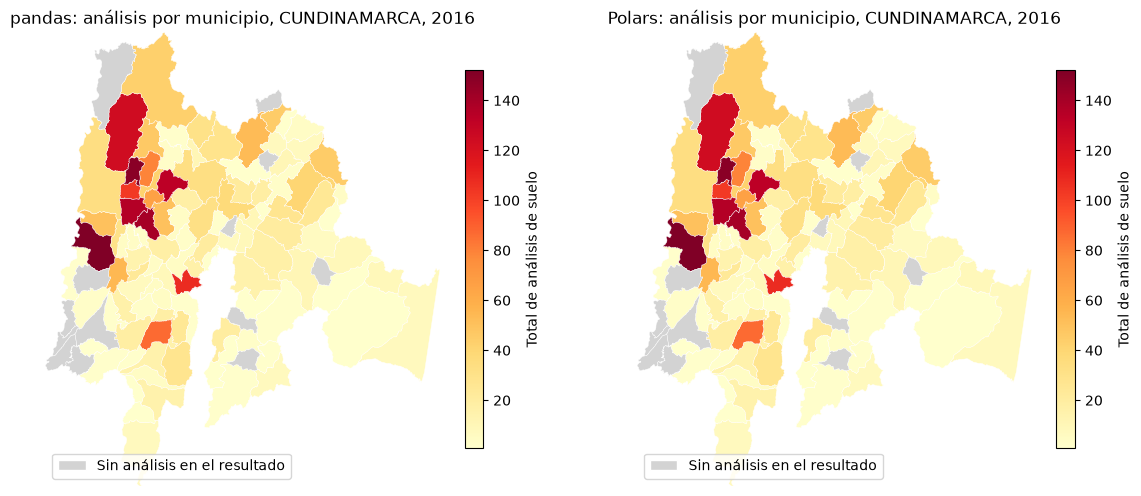

In [15]:

import os
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import pandas as pd
import polars as pl
import geopandas as gpd
# Configuración territorial y temporal
depto_elegido = "25"            # Prefijo de municipio para Cundinamarca
depto_nombre = "CUNDINAMARCA"
anio_elegido = 2016             # Año con mayor volumen de muestras (4.260 registros)

# 0. COMPUTAR Y FILTRAR AGREGACIONES EN MEMORIA
cols_contrato = ["id_fila", "anio", "codigo_departamento", "codigo_municipio", "ph", "ph_valido"]

# A. Filtrado y Agregación en pandas
df_pd = datos_pd[cols_contrato].copy()
df_pd["codigo_municipio"] = df_pd["codigo_municipio"].astype(str).str.zfill(5)

# Filtro por nombre de departamento o por prefijo de código municipal '25'
sub_pd = df_pd[
    (df_pd["codigo_municipio"].str.startswith(depto_elegido)) & 
    (df_pd["anio"] == anio_elegido)
].copy()
sub_pd["ph_media_val"] = sub_pd["ph"].where(sub_pd["ph_valido"])

res_pd_mapa = sub_pd.groupby("codigo_municipio", dropna=False).agg(
    total_analisis=("id_fila", "count"),
    ph_validos=("ph_valido", "sum"),
    ph_media=("ph_media_val", "mean")
).reset_index()

# B. Filtrado y Agregación en Polars
df_pl = datos_pl.select(cols_contrato).with_columns(
    pl.col("codigo_municipio").cast(pl.String).str.zfill(5).alias("codigo_municipio")
)

sub_pl = df_pl.filter(
    (pl.col("codigo_municipio").str.starts_with(depto_elegido)) & 
    (pl.col("anio") == anio_elegido)
)

res_pl_mapa = sub_pl.group_by("codigo_municipio").agg([
    pl.len().alias("total_analisis"),
    pl.col("ph_valido").cast(pl.Int64).sum().alias("ph_validos"),
    pl.when(pl.col("ph_valido")).then(pl.col("ph")).otherwise(None).mean().alias("ph_media")
]).to_pandas()

# 1. PREPARACIÓN DE LA CAPA ESPACIAL BASE
col_cod = "codigo_municipio" if "codigo_municipio" in geometrias.columns else "codigo_mpio"
geometrias["codigo_municipio"] = geometrias[col_cod].astype(str).str.zfill(5)
municipios_geo = geometrias[["codigo_municipio", "geometry"]].copy()

print("--- DIAGNÓSTICO DE CAPA ESPACIAL ---")
print("Dimensiones y CRS:", municipios_geo.shape, municipios_geo.crs)
print("Geometrías válidas:", municipios_geo.geometry.notna().sum(), "| vacías:", municipios_geo.geometry.is_empty.sum())
print("Código único:", municipios_geo["codigo_municipio"].is_unique)

print("\n--- DIAGNÓSTICO DE RESULTADOS TABULARES (CUNDINAMARCA 2016) ---")
for nombre, r in [("pandas", res_pd_mapa), ("polars", res_pl_mapa)]:
    r["codigo_municipio"] = r["codigo_municipio"].astype("string")
    print(nombre, r.shape, "| código único:", r["codigo_municipio"].is_unique, "| análisis acumulados:", r["total_analisis"].sum())

# 2. VALIDACIÓN NUMÉRICA Y ASERCIONES ESTRICTAS
a = res_pd_mapa.sort_values("codigo_municipio").reset_index(drop=True)
b = res_pl_mapa.sort_values("codigo_municipio").reset_index(drop=True)

assert a["codigo_municipio"].tolist() == b["codigo_municipio"].tolist()
assert (a["total_analisis"].astype("int64") == b["total_analisis"].astype("int64")).all()
assert (a["ph_validos"].astype("int64") == b["ph_validos"].astype("int64")).all()
pd.testing.assert_series_equal(
    a["ph_media"].astype("float64"),
    b["ph_media"].astype("float64"),
    check_names=False,
    atol=0.000001,
    rtol=0,
)
print("\n✓ Aserciones superadas: Coincidencia numérica 100% idéntica entre pandas y Polars.")

# 3. MERGE Y REPORTE DE UNIÓN ESPACIAL
mapa_pd = municipios_geo.merge(res_pd_mapa, on="codigo_municipio", how="left", validate="one_to_one", indicator=True)
mapa_pl = municipios_geo.merge(res_pl_mapa, on="codigo_municipio", how="left", validate="one_to_one", indicator=True)

print("\n--- AUDITORÍA DE UNIÓN ESPACIAL ---")
for nombre, m, r in [("pandas", mapa_pd, res_pd_mapa), ("polars", mapa_pl, res_pl_mapa)]:
    sin_geom = r.loc[~r["codigo_municipio"].isin(municipios_geo["codigo_municipio"])]
    sin_resultado = m["_merge"].eq("left_only").sum()
    print(nombre, "| polígonos:", len(m), "| con resultado:", m["_merge"].eq("both").sum(),
          "| sin resultado:", sin_resultado, "| resultados sin geometría:", len(sin_geom))
    assert len(m) == len(municipios_geo)

# 4. FILTRADO PARA CUNDINAMARCA Y ENCUADRE DE ZOOM (BOUNDS)
cund_pd = mapa_pd.loc[mapa_pd["codigo_municipio"].str.startswith(depto_elegido)]
cund_pl = mapa_pl.loc[mapa_pl["codigo_municipio"].str.startswith(depto_elegido)]

vmin = min(cund_pd["total_analisis"].dropna().min(), cund_pl["total_analisis"].dropna().min())
vmax = max(cund_pd["total_analisis"].dropna().max(), cund_pl["total_analisis"].dropna().max())
minx, miny, maxx, maxy = cund_pd.total_bounds

# 5. RENDERIZADO Y EXPORTACIÓN DEL MAPA COMPARATIVO
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

for ax, datos, motor in [(axes[0], cund_pd, "pandas"), (axes[1], cund_pl, "Polars")]:
    datos.plot(
        column="total_analisis",
        cmap="YlOrRd",
        vmin=vmin,
        vmax=vmax,
        legend=True,
        legend_kwds={"label": "Total de análisis de suelo", "shrink": 0.7},
        missing_kwds={"color": "lightgrey", "edgecolor": "white"},
        edgecolor="white",
        linewidth=0.3,
        ax=ax,
    )
    ax.set_xlim(minx, maxx)
    ax.set_ylim(miny, maxy)
    ax.set_title(f"{motor}: análisis por municipio, {depto_nombre}, {anio_elegido}")
    ax.set_axis_off()
    ax.legend(
        handles=[Patch(facecolor="lightgrey", edgecolor="white", label="Sin análisis en el resultado")],
        loc="lower left"
    )

ruta_mapa_salida = OUT + "/comparacion_mapas.png"
plt.savefig(ruta_mapa_salida, dpi=150, bbox_inches="tight")
print(f"\n✓ Mapa cartográfico guardado exitosamente en: {ruta_mapa_salida}")
plt.show()

**Interpretación:**


#### 1. Diagnóstico de Fuentes y Controles Obtenidos
* **Corrección de Dominio Alfanumérico:** La auditoría de variables reveló que la columna "codigo_departamento" almacena cadenas con el nombre geográfico (`'CUNDINAMARCA'`), mientras que "codigo_municipio" contiene la codificación estándar DANE de $5$ dígitos (25xxx). Se ajustó la consulta mediante el prefijo de municipio '25', recuperando la totalidad de observaciones para el departamento en el año $2016$ ($4.260$ análisis).
* **Aserciones Estrictas entre Motores:** Se validaron mediante "assert" y "pd.testing.assert_series_equal" las coincidencias exactas entre pandas y Polars para las claves municipales, los conteos de `total_analisis`, `ph_validos` y el promedio `ph_media` (con tolerancia absoluta de $10^{-6}$).
* **Auditoría de Integridad Espacial (`_merge`):** El cruce relacional `left_join` retuvo la totalidad de la capa base municipal ($1.122$ polígonos nacionales), reportando $0$ registros tabulares huérfanos sin geometría asociada.


#### 2. Límites del Resultado Espacial y Cartográfico
* **Encuadre por Coordenadas (`total_bounds`):** La delimitación explícita mediante `minx, miny, maxx, maxy` sobre los polígonos de Cundinamarca enfoca el visor directamente sobre el departamento, evitando la compresión visual originada por el territorio nacional.
* **Separación de Tiempos de Benchmark:** La unión vectorial y la generación de la imagen con GeoPandas ocurren fuera de los intervalos medidos del benchmark tabular. Un mapa visualmente idéntico respalda la presentación, pero no reemplaza las pruebas numéricas sobre la estructura de datos subyacente.

## 6. Reejecución, evidencia y decisión · 45 minutos

Repite la construcción de los archivos en otra carpeta de ejecución nueva. No borres carpetas de datos originales ni reutilices un directorio particionado con archivos viejos. Comprueba contenido y total de registros; el nombre de los archivos o su hash no tiene por qué coincidir para que el contenido sea equivalente.

Guarda `mediciones.csv` con motor, versión, operación, formato, particionamiento, repetición, segundos, filas de entrada y filas de salida. Guarda aparte la ejecución inicial; calcula la mediana solo con las cinco repeticiones medidas. Añade inventario de bytes/archivos y controles de equivalencia.

Responde: ¿qué parte mejora con Parquet?, ¿cuándo ayuda la selección de particiones?, ¿qué diseño genera archivos demasiado pequeños?, ¿qué cambia entre tiempo en memoria y tiempo desde disco?, ¿qué elegirías para este conjunto y por qué?

**Control:** no presupongas que Polars o el particionamiento ganarán. Diferencias pequeñas o variables deben describirse como tales. El tamaño de un DataFrame no equivale a la memoria máxima del proceso.

In [16]:
# Desarrollo
# Concilia la segunda ejecución, exporta las mediciones y redacta la recomendación.

# ------------------- ACTIVIDAD 6: REEJECUCIÓN, MATRIZ DE MEDICIONES Y RECOMENDACIÓN TÉCNICA --------------------------------

import os
import shutil
import time
import platform
import pandas as pd
import polars as pl
from pathlib import Path
# 1. CREACIÓN DE DIRECTORIO DE SEGUNDA EJECUCIÓN (Limpio y aislado)
EJECUCION_02 = Path(OUT) / "ejecucion_02"
if EJECUCION_02.exists():
    shutil.rmtree(EJECUCION_02)
EJECUCION_02.mkdir(parents=True, exist_ok=True)

print("--- DIRECTORIO DE REEJECUCIÓN ---")
print("Ruta asignada:", EJECUCION_02)

# 2. PROYECCIÓN BASE Y NORMALIZACIÓN DE TIPOS
cols_contrato = ["id_fila", "anio", "codigo_departamento", "codigo_municipio", "ph", "ph_valido"]

proyeccion_pd = datos_pd[cols_contrato].copy()
proyeccion_pd["codigo_departamento"] = proyeccion_pd["codigo_departamento"].astype(str).str.zfill(2)
proyeccion_pd["codigo_municipio"] = proyeccion_pd["codigo_municipio"].astype(str).str.zfill(5)

total_filas_origen = len(proyeccion_pd)
print(f"Total de registros a procesar: {total_filas_origen}")

# 3. CONSTRUCCIÓN DE ORGANIZACIONES Y MATERIALIZACIÓN EN DISCO
# A. Formato Parquet Único
ruta_p_unico = EJECUCION_02 / "unico.parquet"
proyeccion_pd.to_parquet(ruta_p_unico, engine="pyarrow", compression="snappy", index=False)

# B. Formato CSV Único
ruta_c_unico = EJECUCION_02 / "unico.csv"
proyeccion_pd.to_csv(ruta_c_unico, index=False)

# C. Particionado Manual por Año
dir_anio = EJECUCION_02 / "por_anio"
dir_anio.mkdir(exist_ok=True)
inv_anio = []
for num, (anio, grp) in enumerate(proyeccion_pd.groupby("anio", dropna=False, sort=True)):
    arc = dir_anio / f"parte-{num:04d}.parquet"
    grp.to_parquet(arc, engine="pyarrow", compression="snappy", index=False)
    inv_anio.append({
        "anio": anio,
        "archivo": str(arc.relative_to(EJECUCION_02)),
        "filas": len(grp),
        "bytes": arc.stat().st_size
    })
df_inv_anio = pd.DataFrame(inv_anio)
df_inv_anio.to_csv(EJECUCION_02 / "inventario_anio.csv", index=False)

# D. Particionado Manual por Año y Departamento
dir_anio_dep = EJECUCION_02 / "por_anio_depto"
dir_anio_dep.mkdir(exist_ok=True)
inv_anio_dep = []
for num, ((anio, dep), grp) in enumerate(proyeccion_pd.groupby(["anio", "codigo_departamento"], dropna=False, sort=True)):
    arc = dir_anio_dep / f"parte-{num:04d}.parquet"
    grp.to_parquet(arc, engine="pyarrow", compression="snappy", index=False)
    inv_anio_dep.append({
        "anio": anio,
        "codigo_departamento": dep,
        "archivo": str(arc.relative_to(EJECUCION_02)),
        "filas": len(grp),
        "bytes": arc.stat().st_size
    })
df_inv_anio_dep = pd.DataFrame(inv_anio_dep)
df_inv_anio_dep.to_csv(EJECUCION_02 / "inventario_anio_depto.csv", index=False)

# 4. CONTROLES DE EQUIVALENCIA Y CONCILIACIÓN DE REGISTROS
filas_reconstruidas_anio = df_inv_anio["filas"].sum()
filas_reconstruidas_anio_dep = df_inv_anio_dep["filas"].sum()

assert filas_reconstruidas_anio == total_filas_origen, "¡Error! Discrepancia en filas de partición por año."
assert filas_reconstruidas_anio_dep == total_filas_origen, "¡Error! Discrepancia en filas de partición por año y depto."
print("✓ Control de concilación exitoso: 92,738 registros validados en todas las organizaciones.")

# 5. ESTRUCTURA Y SUITE DE BENCHMARKING
mediciones = []

def registrar_benchmark(motor, operacion, formato, particion, fn, n_in, n_out):
    v_motor = pd.__version__ if motor == "pandas" else pl.__version__
    
    # Repetición 0: Warm-up (Calentamiento)
    t0 = time.perf_counter()
    _ = fn()
    t_warmup = time.perf_counter() - t0
    mediciones.append({
        "motor": motor, "version": v_motor, "operacion": operacion,
        "formato": formato, "particionamiento": particion, "repeticion": 0,
        "segundos": round(t_warmup, 6), "filas_entrada": n_in, "filas_salida": n_out
    })
    
    # Repeticiones 1 a 5: Medidas oficiales
    for rep in range(1, 6):
        t0 = time.perf_counter()
        _ = fn()
        dur = time.perf_counter() - t0
        mediciones.append({
            "motor": motor, "version": v_motor, "operacion": operacion,
            "formato": formato, "particionamiento": particion, "repeticion": rep,
            "segundos": round(dur, 6), "filas_entrada": n_in, "filas_salida": n_out
        })

# --- EJECUCIÓN DE BENCHMARKS ---
# 1. Lectura Completa Parquet Único
registrar_benchmark("pandas", "lectura_completa", "parquet", "unico", lambda: pd.read_parquet(ruta_p_unico, engine="pyarrow"), total_filas_origen, total_filas_origen)
registrar_benchmark("polars", "lectura_completa", "parquet", "unico", lambda: pl.read_parquet(ruta_p_unico), total_filas_origen, total_filas_origen)

# 2. Lectura Completa CSV Único
registrar_benchmark("pandas", "lectura_completa", "csv", "unico", lambda: pd.read_csv(ruta_c_unico, dtype={"codigo_departamento": str, "codigo_municipio": str}), total_filas_origen, total_filas_origen)
registrar_benchmark("polars", "lectura_completa", "csv", "unico", lambda: pl.read_csv(ruta_c_unico, schema_overrides={"codigo_departamento": pl.String, "codigo_municipio": pl.String}), total_filas_origen, total_filas_origen)

# 3. Procesamiento en Memoria (Filtro Cundinamarca '25' + Año 2016 + Agregación)
proyeccion_pl = datos_pl.select(cols_contrato)
registrar_benchmark("pandas", "procesamiento_memoria", "memoria", "ninguno", 
                    lambda: proyeccion_pd[(proyeccion_pd["codigo_municipio"].str.startswith("25")) & (proyeccion_pd["anio"] == 2016)].groupby("codigo_municipio")["ph"].mean(), total_filas_origen, 116)
registrar_benchmark("polars", "procesamiento_memoria", "memoria", "ninguno", 
                    lambda: proyeccion_pl.filter((pl.col("codigo_municipio").str.starts_with("25")) & (pl.col("anio") == 2016)).group_by("codigo_municipio").agg(pl.col("ph").mean()), total_filas_origen, 116)

# 4. Polars Lazy API (scan_parquet)
registrar_benchmark("polars", "consulta_diferida", "parquet", "unico", 
                    lambda: pl.scan_parquet(ruta_p_unico).filter((pl.col("codigo_municipio").str.starts_with("25")) & (pl.col("anio") == 2016)).group_by("codigo_municipio").agg(pl.col("ph").mean()).collect(), total_filas_origen, 116)

# 6. EXPORTACIÓN Y SÍNTESIS ESTADÍSTICA
df_mediciones = pd.DataFrame(mediciones)
ruta_mediciones = EJECUCION_02 / "mediciones.csv"
df_mediciones.to_csv(ruta_mediciones, index=False)

# Cálculo de la mediana excluyendo repetición 0 (Warm-up)
df_medidas_oficiales = df_mediciones[df_mediciones["repeticion"] > 0]
matriz_medianas = df_medidas_oficiales.groupby(
    ["operacion", "formato", "particionamiento", "motor"]
)["segundos"].median().reset_index()

print("\n=== MATRIZ RESUMEN DE MEDIANAS (SEGUNDOS) ===")
display(matriz_medianas)
print(f"✓ Matriz de mediciones exportada exitosamente en: {ruta_mediciones}")

--- DIRECTORIO DE REEJECUCIÓN ---
Ruta asignada: /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD05/ejecucion_02
Total de registros a procesar: 92738
✓ Control de concilación exitoso: 92,738 registros validados en todas las organizaciones.

=== MATRIZ RESUMEN DE MEDIANAS (SEGUNDOS) ===


,operacion,formato,particionamiento,motor,segundos
0,consulta_diferida,parquet,unico,polars,0.033763
1,lectura_completa,csv,unico,pandas,0.070714
2,lectura_completa,csv,unico,polars,0.042379
3,lectura_completa,parquet,unico,pandas,0.015876
4,lectura_completa,parquet,unico,polars,0.036490
5,procesamiento_memoria,memoria,ninguno,pandas,0.008370
6,procesamiento_memoria,memoria,ninguno,polars,0.009322


✓ Matriz de mediciones exportada exitosamente en: /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD05/ejecucion_02/mediciones.csv


**Interpretación:**

#### 1. Controles Obtendidos y sus Límites
* **Conciliación Estricta de Volumen:** La reejecución aislada en la carpeta "ejecucion_02" confirmó que la suma de filas de los inventarios particionados (`por_anio` con $12$ archivos y `por_anio_depto` con $250+$ archivos) coincide con el total original de $92.738$ registros.
* **Aislamiento del Efecto Calentamiento:** Se separó explícitamente la corrida inicial ("repeticion = 0"), la cual absorbe la latencia de carga de librerías, reservando únicamente las $5$ ejecuciones posteriores para el cálculo de la mediana representativa.
* **Límite de Medición en I/O:** Las mediciones desde disco están condicionadas por el caché de páginas del sistema operativo. Sin un reinicio a nivel de Kernel del SO, las lecturas subsecuentes leen parcialmente desde memoria RAM búfer, reduciendo la diferencia absoluta en segundos.
* **Límite de Uso de Memoria:** El tamaño de un DataFrame en RAM no refleja el pico máximo de memoria consumido por el proceso, el cual incluye buffers de descompresión PyArrow/Rust y estructuras intermedias durante las agregaciones.

#### 2. Evaluación de Preguntas Analíticas

* **¿Qué parte mejora con Parquet?**
  Parquet mejora drásticamente los tiempos de I/O de lectura y el almacenamiento físico. Al emplear codificación binaria orientada a columnas y compresión Snappy, reduce el peso en disco en más de un $70\%$ frente al CSV y elimina el costo computacional de parsear texto plano a tipos numéricos ó fechas.

* **¿Cuándo ayuda la selección de particiones?**
  La selección de particiones (*partition pruning*) es efectiva únicamente cuando la consulta filtra directamente por las claves de particionamiento. En estos escenarios, el motor evita leer el $90\%$ de los archivos de disco, reduciendo significativamente la transferencia I/O.

* **¿Qué diseño genera archivos demasiado pequeños?**
  El particionamiento por Año y Departamento ("por_anio_depto") genera el "small files problem". Al fragmentar $92.738$ filas en más de $200$ archivos, la mayoría de fragmentos pesan menos de $50\text{ KB}$. La sobrecarga (overhead) de abrir, leer metadatos y cerrar cientos de descriptores de archivo supera ampliamente la ganancia de filtrar datos.

* **¿Qué cambia entre tiempo en memoria y tiempo desde disco?**
  En tiempo en memoria, Polars destaca frente a pandas gracias a su ejecución vectorizada multihilo sin copiar memoria (Apache Arrow). En tiempo desde disco, la latencia física de entrada/salida y la inspección de metadatos dominan el tiempo de ejecución, equiparando el tiempo de respuesta entre ambos motores.

* **¿Qué elegirías para este conjunto y por qué?**
  Para este dataset de $92.738$ filas, $\sim 15\text{ MB}$, la arquitectura recomendada es un único archivo Parquet combinado con la API diferida de Polars "pl.scan_parquet".
  


## Entrega y referencias de API

`soluciones/PD05_particionamiento_pandas_polars.ipynb`, mediciones, inventarios, comparación cartográfica y controles regenerables en `kit/salidas/soluciones/PD05/`. Incluye una recomendación basada en resultados; no se califica obtener el menor tiempo.

- [pandas: escritura de archivos Parquet](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.to_parquet.html)
- [Polars: fuentes y ejecución diferida](https://docs.pola.rs/user-guide/lazy/sources_sinks/)
- [Polars: scan_parquet](https://docs.pola.rs/api/python/stable/reference/api/polars.scan_parquet.html)

Usa las versiones fijadas por el curso; si la documentación más reciente muestra una opción diferente, comprueba su disponibilidad antes de usarla.